# 04 — Clustering: Discovering Data-Driven Player Archetypes

**Project:** Positionless NBA Player Archetypes · **Season:** 2025-26 · **Population:** 379 players with ≥ 500 minutes

The PCA notebook showed that player roles vary along at least three independent axes (interior ↔ perimeter,
on-ball creator ↔ off-ball finisher, disruptor ↔ scorer), while the five listed positions capture essentially only the
first. This notebook groups players **by what they do** using three clustering families with different assumptions:

| Method | Idea | Cluster shape | Membership |
|---|---|---|---|
| **k-means** | Minimise squared distance from each player to the nearest of *k* centres | Round, similar size | Hard (one label) |
| **Hierarchical (Ward)** | Start with every player alone; repeatedly merge the two groups whose merger increases within-group variance the least | Round; builds a full tree | Hard, at any level of the tree |
| **Gaussian Mixture Model** | Each archetype is a Gaussian distribution; each player has a *probability* of belonging to each | Elliptical | **Soft** (a probability per archetype) |

**Structure of the notebook**

| § | Question |
|---|---|
| 1 | Load the feature matrix |
| 2 | How many clusters? Elbow, silhouette, Calinski-Harabasz, Davies-Bouldin, bootstrap stability |
| 3 | Hierarchical view: dendrogram |
| 4 | Gaussian Mixture: model selection (BIC) |
| 5 | Choosing *k*: statistics vs. usefulness |
| 6 | The archetypes: profiles, names, members, map |
| 7 | How solid is each archetype? Silhouettes and per-cluster stability |
| 8 | Soft membership: hybrid players |
| 9 | Do the methods and preprocessing choices agree? |
| 10 | Archetypes vs. listed positions (preview of validation) and export |

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

warnings.filterwarnings('ignore', category=UserWarning)   # KMeans memory-leak notice on some platforms
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 170)
pd.set_option('display.max_colwidth', 120)
sns.set_theme(style='whitegrid', context='notebook')

DATA = Path('../data') if Path('../data').exists() else Path('data')
POS_ORDER = ['PG', 'SG', 'SF', 'PF', 'C']
SEED = 0

---
## 1. Load the Feature Matrix

**Goal.** Load the 13 power-transformed style features (primary clustering input, as decided in the PCA notebook),
plus the raw features (to describe clusters in real units) and the PCA scores (to draw clusters on the player map).

**Why the full 13 features rather than PCA scores?** Redundancy was already removed at feature selection (max VIF 8.8),
so the full matrix carries no duplicated information, and it keeps the 31% of variance outside PC1–PC3. Clustering on
3 PC scores is run as a sensitivity check in §9.

**What to look for.** The three tables must be row-aligned (same players in the same order).

In [2]:
power = pd.read_csv(DATA / 'processed' / 'features_power.csv')
standard = pd.read_csv(DATA / 'processed' / 'features_standard.csv')
raw = pd.read_csv(DATA / 'processed' / 'features_raw.csv')
pcs = pd.read_csv(DATA / 'processed' / 'pca_scores.csv')

META = ['player_id', 'player', 'team', 'pos', 'pos_played', 'age', 'g', 'mp',
        'pg_percent', 'sg_percent', 'sf_percent', 'pf_percent', 'c_percent']
FEAT = [c for c in power.columns if c not in META]
assert all((t['player_id'] == power['player_id']).all() for t in (standard, raw, pcs))
X = power[FEAT].values
print('players:', X.shape[0], '| features:', X.shape[1])
print(FEAT)

players: 379 | features: 13
['x3p_ar', 'corner3_rate', 'mid_share', 'rim_share', 'f_tr', 'usg_percent', 'ast_percent', 'tov_percent', 'percent_assisted_x2p_fg', 'orb_percent', 'drb_percent', 'blk_percent', 'stl_percent']


---
## 2. How Many Clusters? Internal Validation Metrics

**Goal.** Run k-means for k = 2 … 12 and score each solution with five complementary criteria.

| Criterion | What it measures | Better when |
|---|---|---|
| **Inertia** (within-cluster sum of squares) | How tight the clusters are | Lower, but it *always* falls as k grows, so look for an **elbow** rather than the minimum |
| **Silhouette** | For each player: (distance to nearest other cluster − distance to own cluster) / max of the two, averaged | Higher (1 = perfectly separated, 0 = on a border, < 0 = probably misassigned) |
| **Calinski-Harabasz** | Ratio of between-cluster to within-cluster dispersion, adjusted for k | Higher |
| **Davies-Bouldin** | Average similarity of each cluster to its most similar other cluster | Lower |
| **Bootstrap stability** | Refit on 30 resampled versions of the league; Adjusted Rand Index (ARI) between the original and resampled labels | Higher (1 = identical clusters every time) |

**Why several criteria?** Inertia cannot choose *k* by itself, because more clusters always means tighter clusters,
down to one player per cluster. Silhouette, CH and DB penalise over-splitting in different ways. Stability asks a
separate question: would a slightly different season produce the same groups? A clustering that changes completely
under resampling describes noise, not archetypes.

**What to look for.** Whether the criteria agree on a best *k*, and how sharply quality falls as *k* increases.

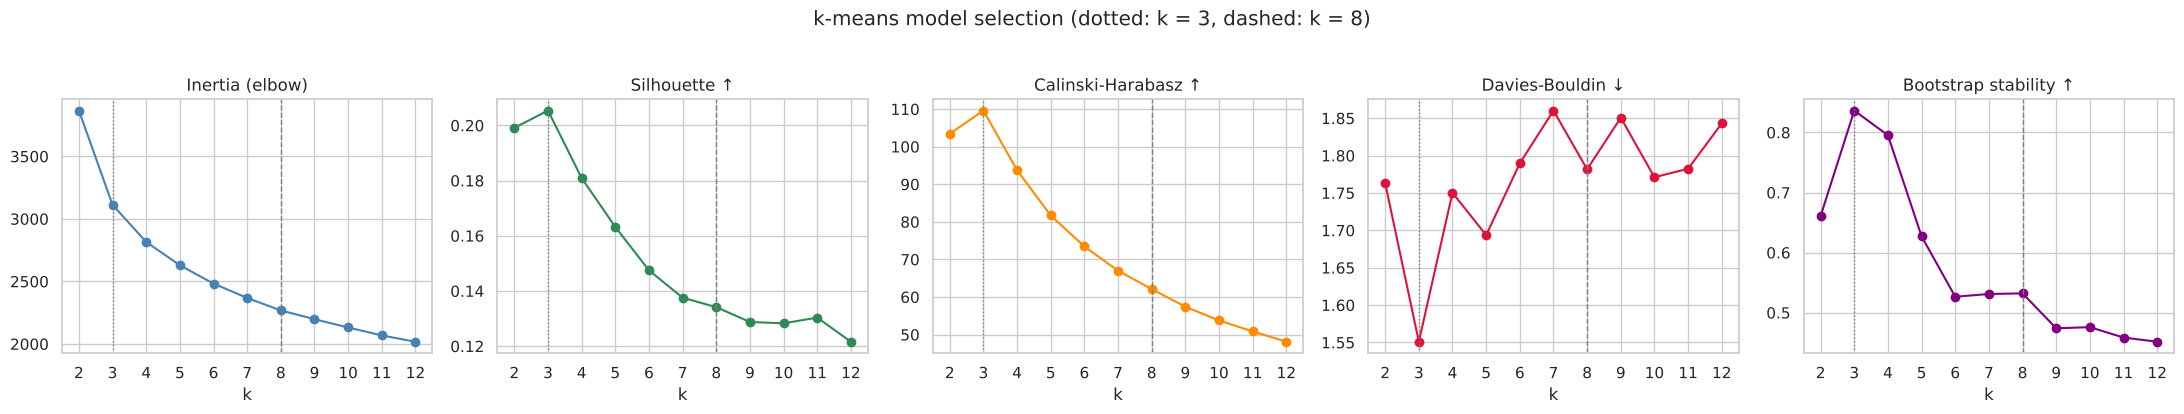

,inertia,silhouette,calinski_harabasz,davies_bouldin,stability (bootstrap ARI),cluster sizes
k,,,,,,
2,3866.255,0.199,103.434,1.763,0.661,"[246, 133]"
3,3112.386,0.205,109.610,1.551,0.837,"[175, 132, 72]"
4,2815.547,0.181,93.741,1.750,0.795,"[132, 101, 90, 56]"
5,2629.435,0.163,81.699,1.694,0.627,"[110, 108, 79, 45, 37]"
6,2482.669,0.147,73.448,1.790,0.527,"[88, 82, 73, 54, 46, 36]"
7,2367.950,0.138,67.004,1.860,0.531,"[77, 64, 63, 59, 55, 33, 28]"
8,2268.173,0.134,62.128,1.782,0.532,"[61, 57, 56, 50, 48, 45, 31, 31]"
9,2198.242,0.129,57.412,1.851,0.474,"[61, 52, 48, 41, 40, 37, 36, 36, 28]"
10,2131.720,0.128,53.762,1.771,0.476,"[48, 48, 44, 39, 38, 38, 34, 33, 31, 26]"


In [3]:
K_RANGE = range(2, 13)
rng = np.random.default_rng(SEED)
rows, km_models = [], {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    km_models[k] = km
    boot = []
    for b in range(30):
        idx = rng.choice(len(X), len(X), replace=True)
        boot.append(adjusted_rand_score(km.labels_, KMeans(n_clusters=k, n_init=10, random_state=b)
                                        .fit(X[idx]).predict(X)))
    rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(X, km.labels_),
                 'calinski_harabasz': calinski_harabasz_score(X, km.labels_),
                 'davies_bouldin': davies_bouldin_score(X, km.labels_),
                 'stability (bootstrap ARI)': np.mean(boot),
                 'cluster sizes': sorted(np.bincount(km.labels_), reverse=True)})
metrics = pd.DataFrame(rows).set_index('k')

fig, ax = plt.subplots(1, 5, figsize=(22, 4))
spec = [('inertia', 'Inertia (elbow)', 'steelblue'), ('silhouette', 'Silhouette ↑', 'seagreen'),
        ('calinski_harabasz', 'Calinski-Harabasz ↑', 'darkorange'), ('davies_bouldin', 'Davies-Bouldin ↓', 'crimson'),
        ('stability (bootstrap ARI)', 'Bootstrap stability ↑', 'purple')]
for a, (col, title, c) in zip(ax, spec):
    a.plot(metrics.index, metrics[col], 'o-', color=c)
    a.axvline(3, color='grey', ls=':', lw=1); a.axvline(8, color='grey', ls='--', lw=1)
    a.set(title=title, xlabel='k', xticks=list(K_RANGE))
plt.suptitle('k-means model selection (dotted: k = 3, dashed: k = 8)', y=1.03)
plt.tight_layout(); plt.show()
metrics.round(3)

### Findings: Internal metrics
- **Every criterion except inertia points to k = 3**: highest silhouette (0.205), highest Calinski-Harabasz, lowest
  Davies-Bouldin, and the highest bootstrap stability (ARI ≈ 0.84).
- **The absolute silhouette values are low** (0.12–0.21 at every k). Values below about 0.25 mean the groups are not
  well separated: most players sit closer to a cluster border than to a cluster core. This is not a modelling failure. It
  is the main empirical finding of the EDA and PCA, seen from another angle: **NBA roles form a continuum, not
  islands.** Any clustering is a partition of a continuous space.
- **Inertia has no sharp elbow.** The curve bends gently around k = 3–4, then keeps falling smoothly, which is again
  the signature of continuous structure.
- **Stability drops in two steps:** about 0.8 for k = 3–4, about 0.6 at k = 5, then a long plateau around 0.45–0.53 from
  k = 6 to 12. Beyond k = 5, finer splits are reproducible only *partly*, and no particular k in 6–12 is clearly
  better than its neighbours.

---
## 3. Hierarchical Clustering (Ward Linkage)

**Goal.** Build the full merge tree of all 379 players and see whether it has natural cut points.

**How it works.** Agglomerative clustering starts with every player as its own cluster and repeatedly merges the pair
of clusters whose union increases the total within-cluster variance the least (**Ward's criterion**, the same objective
as k-means). The **dendrogram** records every merge; the height of a merge is the cost of joining those two groups.
A natural number of clusters shows up as a **long vertical gap**: groups that are only merged at a much greater cost
than everything below them.

The **cophenetic correlation** measures how faithfully the tree's merge heights reproduce the original pairwise
distances between players (1 = perfectly).

**What to look for.** The largest gaps in merge height, and where cuts at 3 and 8 clusters fall.

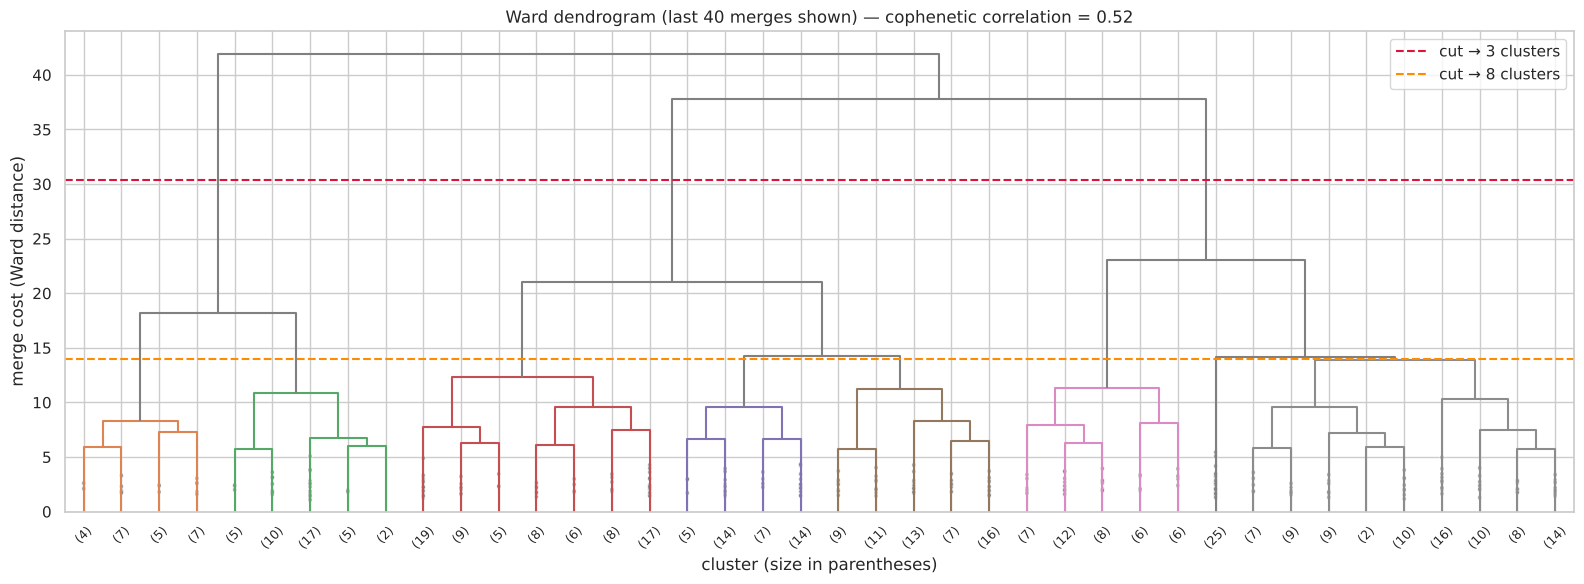

Ward silhouette by k: {2: 0.232, 3: 0.176, 4: 0.158, 5: 0.119, 6: 0.117, 7: 0.107, 8: 0.085, 9: 0.09, 10: 0.093, 11: 0.096, 12: 0.091}


,clusters after merge,merge height,gap to next merge
0,1,41.92,4.14
1,2,37.78,14.74
2,3,23.04,2.02
3,4,21.03,2.84
4,5,18.19,3.92
5,6,14.27,0.12
6,7,14.15,0.28
7,8,13.87,1.50
8,9,12.37,1.07
9,10,11.30,0.08


In [4]:
Z = linkage(X, method='ward')
coph = cophenet(Z, pdist(X))[0]

fig, ax = plt.subplots(figsize=(16, 6))
dendrogram(Z, truncate_mode='lastp', p=40, show_contracted=True, color_threshold=Z[-8, 2] + 1e-9,
           above_threshold_color='grey', ax=ax, leaf_font_size=9)
ax.axhline((Z[-3, 2] + Z[-2, 2]) / 2, color='crimson', ls='--', label='cut → 3 clusters')
ax.axhline((Z[-8, 2] + Z[-7, 2]) / 2, color='darkorange', ls='--', label='cut → 8 clusters')
ax.set(title=f'Ward dendrogram (last 40 merges shown) — cophenetic correlation = {coph:.2f}',
       xlabel='cluster (size in parentheses)', ylabel='merge cost (Ward distance)')
ax.legend(); plt.tight_layout(); plt.show()

heights = Z[::-1, 2][:12]
gaps = pd.DataFrame({'clusters after merge': range(1, 13), 'merge height': heights,
                     'gap to next merge': np.r_[heights[:-1] - heights[1:], np.nan]}).round(2)
ward_sil = {k: silhouette_score(X, fcluster(Z, k, 'maxclust')) for k in K_RANGE}
print('Ward silhouette by k:', {k: round(v, 3) for k, v in ward_sil.items()})
gaps.head(10)

### Findings: Hierarchical structure
- **The largest gap in the tree (≈ 14.7) sits between the 3-cluster and 2-cluster levels**: merging the last three
  groups into two costs 37.8, against 23.0 for the merge before it. Cutting inside that gap gives **3 clusters**, the
  same answer as §2.
- A second, much smaller gap (≈ 3.9) supports 6 clusters. Between 6 and 8 clusters the merge heights are almost flat
  (14.3, 14.2, 13.9), meaning those splits are about equally (un)justified: **three robust families, then gradual
  subdivision with no natural stopping point.**
- The cophenetic correlation (≈ 0.52) is moderate: the tree is a reasonable but simplified summary of the distance
  structure, as expected for continuous data.
- Ward has a higher silhouette than k-means at k = 2 (0.23 vs. 0.20) but a *lower* one at every k ≥ 3. Both optimise
  the same variance criterion, but k-means can reassign players after the fact while hierarchical merges are permanent.
  **k-means is therefore used as the primary hard clustering**, and the Ward tree as an independent cross-check (§9).

---
## 4. Gaussian Mixture Models: Model Selection with BIC

**Goal.** Fit Gaussian Mixture Models for k = 1 … 12 with three covariance structures and select with the **Bayesian
Information Criterion (BIC)**.

**Why GMM?** k-means assumes round clusters and gives hard labels. A GMM models each archetype as a multivariate
Gaussian with its own centre (and, depending on the structure, its own shape), and assigns every player a
**probability** of belonging to each archetype. On a continuum, this is the honest way to describe a player who is
"60% wing, 40% big".

**Covariance structures**

| Type | Each component has… | Parameters per component (13 features) |
|---|---|---|
| `full` | its own unrestricted covariance (any ellipse orientation) | 13 means + 91 covariances |
| `diag` | its own variances, no correlations | 13 + 13 |
| `tied` | one covariance matrix *shared* by all components | 13 (+ 91 shared once) |

**BIC** = −2 · log-likelihood + (number of parameters) · log(n). It rewards fit but penalises complexity. **Lower is
better.** With 379 players, a `full` model with 8 components has over 800 parameters, and BIC will expose that.

**What to look for.** The covariance type with the lowest BIC overall, and the *k* at which each curve bottoms out.

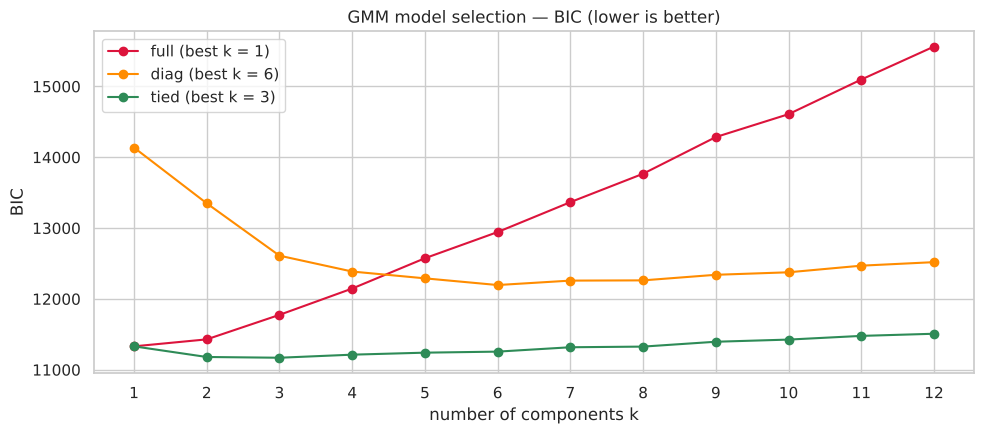

,1,2,3,4,5,6,7,8,9,10,11,12
full,11331,11429,11775,12146,12574,12944,13366,13767,14285,14608,15097,15563
diag,14137,13350,12611,12387,12291,12196,12259,12262,12341,12376,12469,12519
tied,11331,11180,11170,11213,11241,11256,11318,11327,11396,11426,11478,11508


In [5]:
bic = {}
for ct in ['full', 'diag', 'tied']:
    bic[ct] = [GaussianMixture(k, covariance_type=ct, n_init=5, random_state=SEED).fit(X).bic(X) for k in range(1, 13)]
bic = pd.DataFrame(bic, index=range(1, 13))

fig, ax = plt.subplots(figsize=(10, 4.5))
for ct, c in zip(bic, ['crimson', 'darkorange', 'seagreen']):
    ax.plot(bic.index, bic[ct], 'o-', color=c, label=f'{ct} (best k = {bic[ct].idxmin()})')
ax.set(title='GMM model selection — BIC (lower is better)', xlabel='number of components k', ylabel='BIC',
       xticks=list(bic.index)); ax.legend(); plt.tight_layout(); plt.show()
bic.round(0).astype(int).T

### Findings: GMM selection
- **`tied` has the lowest BIC at every k ≥ 2**, with its minimum at **k = 3**, the same answer as k-means and the
  dendrogram. A shared covariance lets the model capture the correlations between features (rim shots ↔ rebounds ↔
  blocks) once, instead of re-estimating them for each archetype.
- **`full` is penalised so heavily that BIC prefers a single component**: 379 players cannot support 104 free
  parameters per archetype. `diag` ignores correlations and fits poorly at small k.
- **Decision:** the soft-membership analysis (§8) uses a **tied-covariance GMM**, initialised at the k-means centres so
  that its components correspond to the k-means archetypes.

---
## 5. Choosing *k*: What the Statistics Say vs. What the Project Needs

All three methods agree that the most *separated* and *stable* partition is **k = 3**. Before accepting it, it is
worth looking at what those three groups are.

**Goal.** Inspect the k = 3 solution in real units.

**What to look for.** Whether three groups describe genuinely new roles, or mostly re-discover the traditional
guard / wing / big split.

In [6]:
lab3 = km_models[3].labels_
prof3 = raw[FEAT].groupby(lab3).median()
prof3.insert(0, 'players', np.bincount(lab3))
prof3[['PC1', 'PC2', 'PC3']] = pcs[['PC1', 'PC2', 'PC3']].groupby(lab3).mean()
display(prof3.round(2))
print('listed positions per cluster:')
pd.crosstab(lab3, power['pos'])[POS_ORDER]

,players,x3p_ar,corner3_rate,mid_share,rim_share,f_tr,usg_percent,ast_percent,tov_percent,percent_assisted_x2p_fg,orb_percent,drb_percent,blk_percent,stl_percent,PC1,PC2,PC3
0,175,0.54,0.17,0.07,0.20,0.20,16.50,10.3,11.20,0.65,4.2,12.50,1.40,1.6,-0.47,-1.49,0.04
1,132,0.40,0.07,0.18,0.17,0.28,23.65,22.6,12.75,0.39,2.7,12.05,1.00,1.7,-1.15,1.77,0.05
2,72,0.11,0.02,0.06,0.44,0.35,16.80,10.1,13.40,0.67,11.2,21.10,3.55,1.5,3.26,0.38,-0.20


listed positions per cluster:


pos,PG,SG,SF,PF,C
row_0,,,,,
0,13,62,41,50,9
1,54,38,24,9,7
2,1,1,3,15,52


**Reading the k = 3 solution.** The three groups are:
1. **Bigs** (≈ 72 players): rim share 0.44, ORB% 11, BLK% 3.6, high PC1.
2. **On-ball creators** (≈ 132): usage ≈ 24%, AST% ≈ 23%, high PC2.
3. **Off-ball perimeter players** (≈ 175): 3PA rate 0.54, corner-3 rate 0.17, more than 60% of 2s assisted, low PC2.

These are robust and meaningful, and already more informative than positions, because group 2 (creators) cuts across
PG, SG and SF, and group 3 contains more PFs (50) than SFs (41). But three groups are too coarse for the project's purpose: a
"big" group that contains both Rudy Gobert and Nikola Jokić, or an "off-ball" group that contains both a pure corner
shooter and a ball-hawking defender, does not describe roles at the level at which teams think about rosters.

### The choice: a two-level taxonomy

| Level | k | Justification |
|---|---|---|
| **Families** | **3** | Statistical optimum: best silhouette, CH, DB, BIC; stability ≈ 0.84 |
| **Archetypes** | **8** | Useful granularity; within the 6–12 plateau all metrics are nearly flat (silhouette 0.12–0.15, stability 0.45–0.53), so the choice there is made on *interpretability*. At k = 8 every cluster has a distinct, nameable profile; k = 6 merges primary creators with shot-making guards, k = 7 has no separate defensive-disruptor role, and from k = 9 stability drops again (≈ 0.47) |

The cost of k = 8 is lower stability. Rather than hide it, §7 measures it **per archetype**, and §8 uses soft
membership to identify the players whose label should not be trusted.

---
## 6. The Eight Archetypes

### 6a. Feature profile of each cluster

**Goal.** Describe each of the eight k-means clusters by its average position on every feature.

**How to read the heatmap.** Values are cluster means of the *scaled* features, i.e. how many standard deviations the
average member sits above (red) or below (blue) the league average. Reading across a row gives the cluster's
"fingerprint": what its members do more, and less, than a typical player.

**What to look for.** The two or three strongest colours in each row: they determine the archetype's name.

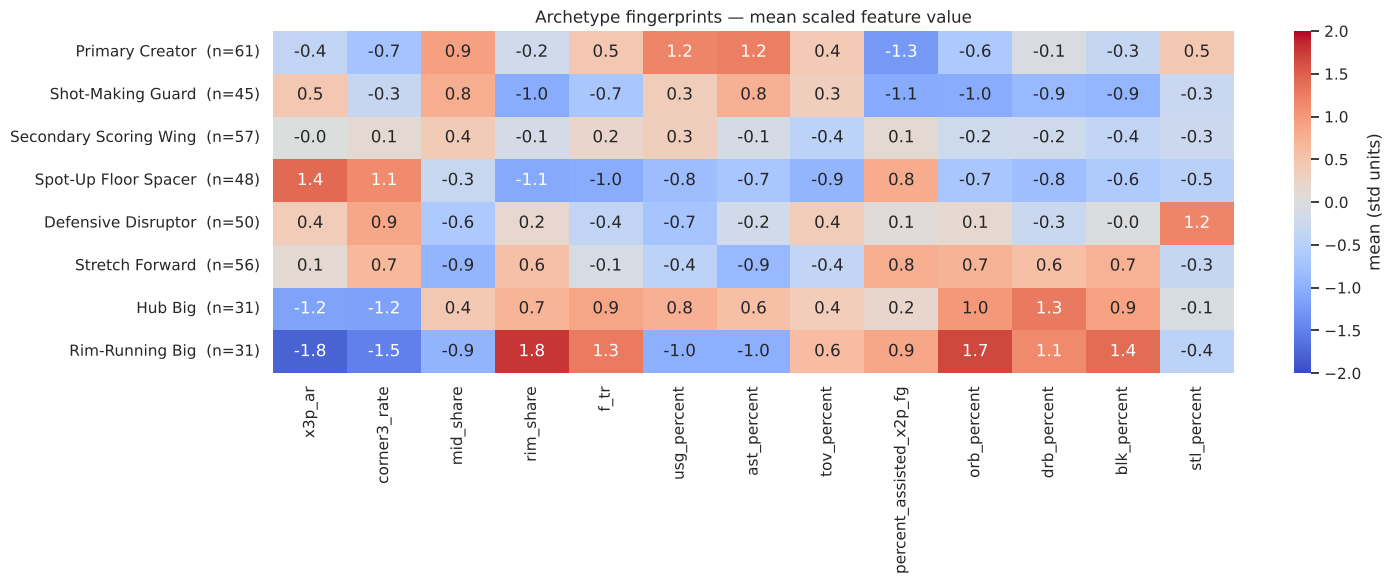

In [7]:
K = 8
km8 = km_models[K]
lab8 = km8.labels_

# Names are attached through an anchor player (a clear, well-known member of each cluster),
# so they stay correct even if cluster numbering changes between library versions.
ANCHORS = {
    'Rudy Gobert':         'Rim-Running Big',
    'Alperen Şengün':      'Hub Big',
    "De'Aaron Fox":        'Primary Creator',
    'Malik Monk':          'Shot-Making Guard',
    'Desmond Bane':        'Secondary Scoring Wing',
    'Luguentz Dort':       'Spot-Up Floor Spacer',
    'Herbert Jones':       'Defensive Disruptor',
    'P.J. Washington':     'Stretch Forward',
}
cid = {power.index[power['player'] == p][0]: n for p, n in ANCHORS.items()}
NAMES = {lab8[i]: n for i, n in cid.items()}
assert len(NAMES) == K, 'each anchor player must fall in a different cluster'
ORDER = ['Primary Creator', 'Shot-Making Guard', 'Secondary Scoring Wing', 'Spot-Up Floor Spacer',
         'Defensive Disruptor', 'Stretch Forward', 'Hub Big', 'Rim-Running Big']
archetype = pd.Series([NAMES[l] for l in lab8], name='archetype')

fingerprint = power[FEAT].groupby(archetype).mean().loc[ORDER]
fingerprint.insert(0, 'n', archetype.value_counts().loc[ORDER])
fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(fingerprint[FEAT], annot=True, fmt='.1f', cmap='coolwarm', center=0, vmin=-2, vmax=2,
            cbar_kws={'label': 'mean (std units)'}, ax=ax)
ax.set_yticklabels([f'{n}  (n={fingerprint.loc[n, "n"]})' for n in ORDER], rotation=0)
ax.set(title='Archetype fingerprints — mean scaled feature value', xlabel='', ylabel='')
plt.tight_layout(); plt.show()

### 6b. Profiles in real units and representative members

**Goal.** Translate the fingerprints into basketball numbers (medians of the *raw* features) and list each archetype's
most typical members, the players closest to the cluster centre.

**What to look for.** Whether the representative players clearly share a role, and how many different *listed*
positions each archetype draws from.

In [8]:
profile = raw[FEAT].groupby(archetype).median().loc[ORDER]
profile.insert(0, 'players', archetype.value_counts().loc[ORDER])
for p in ['PC1', 'PC2', 'PC3']:
    profile[p] = pcs[p].groupby(archetype).mean().loc[ORDER]
display(profile.round(2))

dist_to_centre = ((X - km8.cluster_centers_[lab8]) ** 2).sum(axis=1)
members = {}
for n in ORDER:
    m = power.loc[archetype == n].assign(d=dist_to_centre[archetype == n]).nsmallest(6, 'd')
    members[n] = {'most typical members': ', '.join(m['player']),
                  'listed positions': ' · '.join(f'{p} {c}' for p, c in
                                                 power.loc[archetype == n, 'pos'].value_counts().items())}
pd.DataFrame(members).T

,players,x3p_ar,corner3_rate,mid_share,rim_share,f_tr,usg_percent,ast_percent,tov_percent,percent_assisted_x2p_fg,orb_percent,drb_percent,blk_percent,stl_percent,PC1,PC2,PC3
archetype,,,,,,,,,,,,,,,,,
Primary Creator,61,0.34,0.05,0.20,0.20,0.29,25.90,25.90,13.50,0.34,2.70,13.20,1.1,1.9,-0.94,2.47,0.27
Shot-Making Guard,45,0.51,0.08,0.19,0.12,0.18,21.10,20.70,13.10,0.39,2.10,10.20,0.7,1.5,-2.38,0.95,0.08
Secondary Scoring Wing,57,0.42,0.11,0.14,0.21,0.26,20.40,12.70,10.90,0.58,3.60,12.70,1.1,1.5,-0.45,0.07,-0.63
Spot-Up Floor Spacer,48,0.70,0.20,0.08,0.12,0.13,15.15,9.55,9.20,0.71,2.80,10.30,1.0,1.3,-1.83,-2.49,-0.54
Defensive Disruptor,50,0.50,0.18,0.06,0.24,0.20,15.30,12.60,13.05,0.56,4.85,12.65,1.5,2.4,-0.07,-1.08,1.52
Stretch Forward,56,0.45,0.16,0.04,0.32,0.23,16.65,8.40,11.00,0.70,6.65,17.70,2.6,1.5,1.40,-1.57,-0.29
Hub Big,31,0.19,0.03,0.15,0.33,0.36,23.40,17.70,13.50,0.58,8.30,23.40,3.0,1.6,2.13,1.86,-0.47
Rim-Running Big,31,0.01,0.00,0.04,0.63,0.40,13.70,8.90,14.00,0.69,13.40,21.20,4.1,1.5,4.40,0.21,-0.10


,most typical members,listed positions
Primary Creator,"De'Aaron Fox, Donovan Mitchell, Jeremiah Fears, Austin Reaves, Jalen Williams, Ajay Mitchell",PG 31 · SF 13 · SG 12 · PF 5
Shot-Making Guard,"Caleb Love, Malik Monk, Tre Mann, Cam Spencer, Tre Johnson, Bones Hyland",PG 23 · SG 19 · SF 2 · C 1
Secondary Scoring Wing,"Desmond Bane, Will Riley, Quentin Grimes, Brice Sensabaugh, Kyle Kuzma, Jaden Ivey",SG 21 · SF 18 · PF 15 · PG 2 · C 1
Spot-Up Floor Spacer,"Luguentz Dort, Ethan Thompson, Tristan Da Silva, Ben Sheppard, Daeqwon Plowden, Vít Krejčí",SG 20 · SF 15 · PF 8 · PG 5
Defensive Disruptor,"Herbert Jones, Dalen Terry, Aaron Wiggins, Rayan Rupert, Jake LaRavia, Jamir Watkins",SG 24 · SF 11 · PF 9 · PG 6
Stretch Forward,"P.J. Washington, Jaylon Tyson, Leonard Miller, Onyeka Okongwu, Taylor Hendricks, Guerschon Yabusele",PF 25 · C 19 · SF 7 · SG 5
Hub Big,"Evan Mobley, Alperen Şengün, Karl-Anthony Towns, Scottie Barnes, Alex Sarr, Amen Thompson",C 19 · PF 9 · SF 2 · PG 1
Rim-Running Big,"Daniel Gafford, Neemias Queta, Moussa Diabaté, Goga Bitadze, Rudy Gobert, Isaiah Jackson",C 28 · PF 3


### Findings: The archetypes

| Archetype | n | Signature (median) | Typical members |
|---|---|---|---|
| **Primary Creator** | 61 | Usage 26%, AST% 26%, only 34% of 2s assisted, mid-range share 0.20 | Fox, D. Mitchell, Reaves, Fears, J. Williams |
| **Shot-Making Guard** | 45 | Usage 21%, AST% 21%, 3PA rate 0.51, mid-range 0.19, very low rebounding | Love, Monk, Mann, Spencer, Hyland |
| **Secondary Scoring Wing** | 57 | Close to league average on almost everything; usage 20%, low TOV% | Bane, Riley, Grimes, Sensabaugh, Kuzma |
| **Spot-Up Floor Spacer** | 48 | 3PA rate 0.70, corner-3 rate 0.20, usage 15%, 71% of 2s assisted, lowest TOV% | Dort, Thompson, Da Silva, Sheppard, Plowden |
| **Defensive Disruptor** | 50 | Highest steal rate (2.4%), high PC3, low usage, 3PA rate 0.50 | Herb Jones, Terry, Wiggins, Rupert, LaRavia |
| **Stretch Forward** | 56 | 3PA rate 0.45 *and* rim share 0.32, DRB% 18, BLK% 2.6, low AST% | P.J. Washington, Tyson, Okongwu, Hendricks, Collins |
| **Hub Big** | 31 | Big-man rebounding (DRB% 23) and rim work *plus* usage 23% and AST% 18% | Mobley, Şengün, Towns, Barnes, Sarr, A. Thompson |
| **Rim-Running Big** | 31 | Almost no threes (3PA rate 0.01), rim share 0.63, ORB% 13, BLK% 4.1 | Gafford, Queta, Diabaté, Bitadze, Gobert, Capela |

Observations:
- **Only one archetype is a single position.** Rim-Running Bigs are almost all listed centres. Every other archetype
  draws from at least three listed positions, e.g. *Primary Creator* mixes PGs, SFs, SGs and PFs; *Stretch Forward*
  mixes PFs, Cs, SFs and SGs.
- **"Centre" splits into three different jobs:** Rim-Running Big (finisher and protector), Hub Big (the offense runs
  through them: Jokić, Şengün, Giannis and Wembanyama are here), and Stretch Forward (spacing big).
- **"Guard" splits into three:** Primary Creator, Shot-Making Guard (scoring off the dribble with less playmaking load),
  and players who are guards by size but Spot-Up Floor Spacers or Defensive Disruptors by role.
- **Secondary Scoring Wing** is the "middle of the distribution" archetype: average on most axes. It is a real role
  (the second or third option on the wing) but, as §7 shows, also the least sharply defined group.

### 6c. The archetypes on the PCA map

**Goal.** Draw every player on the PC1 × PC2 plane from the PCA notebook (interior ↔ perimeter, off-ball ↔ on-ball)
and colour by archetype, with archetype centres and well-known players labelled.

**What to look for.** Archetypes should occupy distinct *regions* of the map, but with soft borders where they meet,
which is consistent with the low silhouette values. Archetypes that overlap in PC1–PC2 (e.g. Spot-Up Floor Spacer and
Defensive Disruptor and Stretch Forward) should be separated by PC3, so a second panel shows PC1 × PC3.

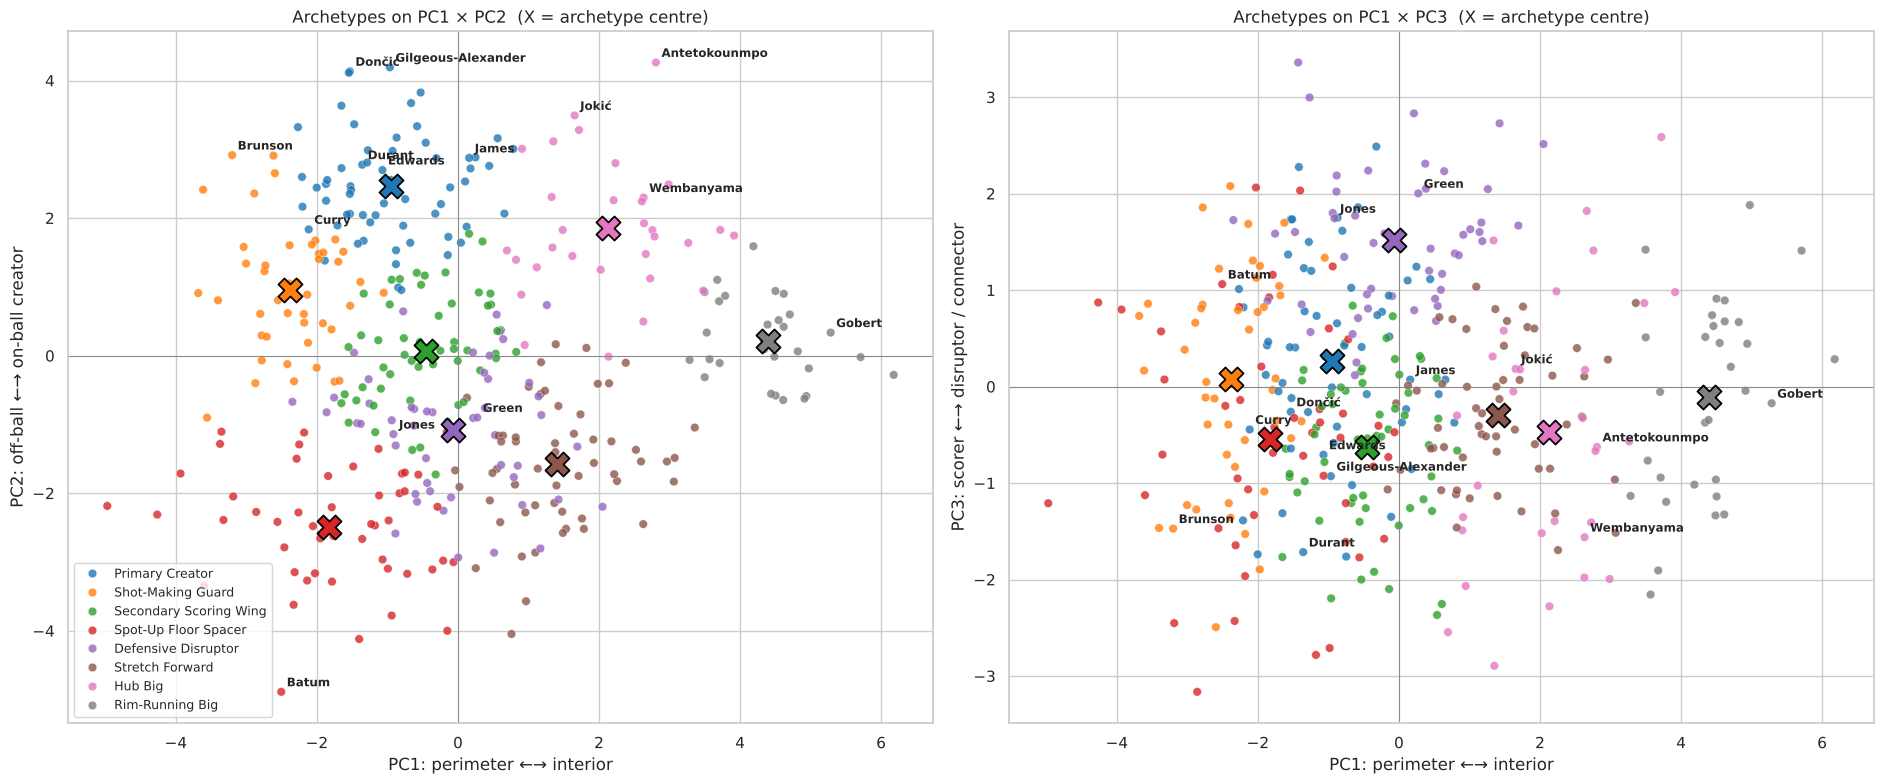

In [9]:
ARCH_PAL = dict(zip(ORDER, sns.color_palette('tab10', K)))
STARS = ['Nikola Jokić', 'Giannis Antetokounmpo', 'Shai Gilgeous-Alexander', 'Luka Dončić', 'Stephen Curry',
         'Rudy Gobert', 'Victor Wembanyama', 'Draymond Green', 'LeBron James', 'Kevin Durant', 'Jalen Brunson',
         'Herbert Jones', 'Nicolas Batum', 'Anthony Edwards']
mp = pd.concat([power[['player', 'pos']], pcs[['PC1', 'PC2', 'PC3']], archetype], axis=1)

fig, ax = plt.subplots(1, 2, figsize=(19, 8))
for a, (xc, yc, xl, yl) in zip(ax, [('PC1', 'PC2', 'PC1: perimeter ←→ interior', 'PC2: off-ball ←→ on-ball creator'),
                                    ('PC1', 'PC3', 'PC1: perimeter ←→ interior', 'PC3: scorer ←→ disruptor / connector')]):
    sns.scatterplot(data=mp, x=xc, y=yc, hue='archetype', hue_order=ORDER, palette=ARCH_PAL, s=38, alpha=0.8,
                    edgecolor='white', linewidth=0.3, ax=a)
    cen = mp.groupby('archetype')[[xc, yc]].mean()
    for n, (x, y) in cen.iterrows():
        a.scatter(x, y, s=300, marker='X', color=ARCH_PAL[n], edgecolor='black', linewidth=1.3, zorder=5)
    for s in STARS:
        r = mp[mp['player'] == s]
        a.annotate(s.split()[-1], (r[xc].iat[0], r[yc].iat[0]), xytext=(4, 4), textcoords='offset points',
                   fontsize=8.5, weight='bold', zorder=6)
    a.axhline(0, color='grey', lw=0.6); a.axvline(0, color='grey', lw=0.6)
    a.set(xlabel=xl, ylabel=yl, title=f'Archetypes on {xc} × {yc}  (X = archetype centre)')
ax[0].legend(loc='lower left', fontsize=9); ax[1].get_legend().remove()
plt.tight_layout(); plt.show()

**Reading the map.**
- The archetypes tile the PC1 × PC2 plane in an orderly way: creators at the top, spot-up shooters bottom-left,
  rim-runners far right, hub bigs top-right, stretch forwards bottom-right, secondary wings in the middle.
- **Defensive Disruptors sit in the middle of the left panel, overlapping Stretch Forwards and Secondary Scoring
  Wings, but separate clearly upward on PC3** (right panel, centre at +1.5 vs. −0.3 to −0.6 for those two). This is
  why clustering uses all features and not only the first two components.
- Stars land where their style suggests: Jokić, Giannis and Wembanyama among the Hub Bigs; SGA, Dončić, LeBron, Curry
  and Edwards among the Primary Creators; Draymond Green among the Defensive Disruptors, next to the connector forwards.

---
## 7. How Solid Is Each Archetype?

### 7a. Silhouette plot

**Goal.** Show the silhouette value of *every* player, grouped by archetype.

**How to read it.** Each horizontal bar is one player. A long bar to the right means the player clearly belongs to
their archetype; a bar near 0 means the player sits on the border with another archetype; a bar to the *left* (negative)
means the player is, on average, closer to another archetype's members than to their own. The dashed line is the
overall average.

**What to look for.** Archetypes whose bars are mostly long (well-defined) versus mostly short or negative (fuzzy).

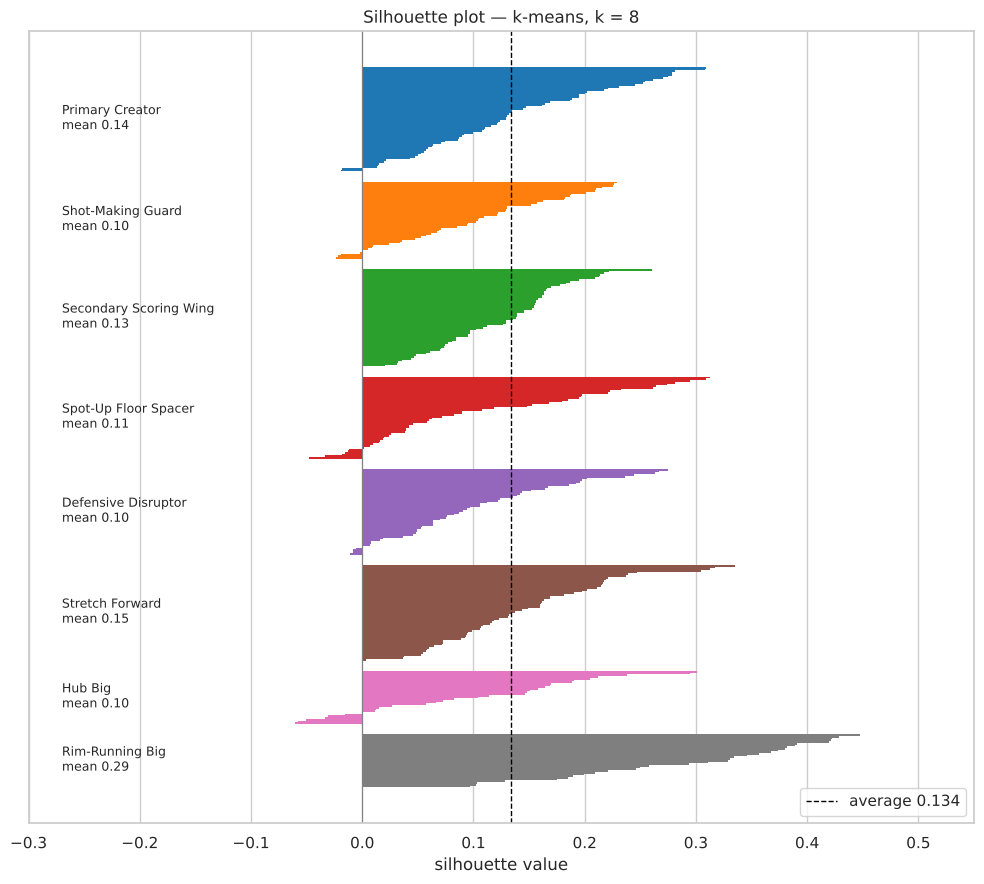

,mean silhouette,% negative
archetype,,
Primary Creator,0.14,3.28
Shot-Making Guard,0.10,11.11
Secondary Scoring Wing,0.13,0.00
Spot-Up Floor Spacer,0.11,12.50
Defensive Disruptor,0.10,10.00
Stretch Forward,0.15,0.00
Hub Big,0.10,19.35
Rim-Running Big,0.29,0.00


In [10]:
sil = silhouette_samples(X, lab8)
fig, ax = plt.subplots(figsize=(10, 9))
y = 0
for n in ORDER[::-1]:
    v = np.sort(sil[archetype == n])
    ax.barh(np.arange(y, y + len(v)), v, height=1.0, color=ARCH_PAL[n], edgecolor='none')
    ax.text(-0.27, y + len(v) / 2, f'{n}\nmean {v.mean():.2f}', va='center', fontsize=9)
    y += len(v) + 6
ax.axvline(sil.mean(), color='black', ls='--', lw=1, label=f'average {sil.mean():.3f}')
ax.axvline(0, color='grey', lw=0.8)
ax.set(xlim=(-0.3, 0.55), yticks=[], xlabel='silhouette value', title='Silhouette plot — k-means, k = 8')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

sil_tab = pd.DataFrame({'mean silhouette': pd.Series(sil).groupby(archetype).mean(),
                        '% negative': pd.Series(sil < 0).groupby(archetype).mean() * 100}).loc[ORDER].round(2)
sil_tab

### 7b. Per-archetype bootstrap stability (Jaccard)

**Goal.** Measure separately for each archetype whether it re-appears when the clustering is re-run on resampled data.

**Method.** Draw 100 bootstrap samples of the players, re-run k-means on each, and for every original archetype find
the best-matching resampled cluster. The **Jaccard similarity** (shared members ÷ combined members) of that best match,
averaged over the 100 samples, is the archetype's stability. A common rule of thumb: **> 0.85 highly stable,
0.6–0.85 a valid pattern, 0.5–0.6 indicative of structure, < 0.5 unstable.**

**What to look for.** Which archetypes would survive a different season's data, and which are partly an artefact of
where k-means draws borders in a continuous region.

In [11]:
rng = np.random.default_rng(1)
jac = np.zeros((100, K))
for b in range(100):
    idx = np.unique(rng.choice(len(X), len(X), replace=True))
    lb = KMeans(n_clusters=K, n_init=10, random_state=b).fit(X[idx]).labels_
    for c in range(K):
        a = set(idx[lab8[idx] == c])
        jac[b, c] = max(len(a & set(idx[lb == d])) / len(a | set(idx[lb == d])) for d in range(K))
stab = pd.Series(jac.mean(axis=0), index=[NAMES[c] for c in range(K)]).loc[ORDER]

quality = sil_tab.assign(**{'bootstrap Jaccard': stab.round(2)})
quality['verdict'] = pd.cut(quality['bootstrap Jaccard'], [0, 0.5, 0.6, 0.85, 1],
                            labels=['unstable', 'indicative', 'valid pattern', 'highly stable'])
quality

,mean silhouette,% negative,bootstrap Jaccard,verdict
archetype,,,,
Primary Creator,0.14,3.28,0.61,valid pattern
Shot-Making Guard,0.10,11.11,0.52,indicative
Secondary Scoring Wing,0.13,0.00,0.46,unstable
Spot-Up Floor Spacer,0.11,12.50,0.69,valid pattern
Defensive Disruptor,0.10,10.00,0.53,indicative
Stretch Forward,0.15,0.00,0.64,valid pattern
Hub Big,0.10,19.35,0.58,indicative
Rim-Running Big,0.29,0.00,0.86,highly stable


### Findings: Archetype quality
- **Rim-Running Big is the only highly stable archetype** (Jaccard ≈ 0.86, highest silhouette): a truly distinct role
  at the edge of the feature space.
- **Spot-Up Floor Spacer, Stretch Forward and Primary Creator are valid patterns** (≈ 0.6–0.7).
- **Hub Big, Defensive Disruptor and Shot-Making Guard are indicative** (≈ 0.5–0.6): the role is real, but its border
  with neighbouring archetypes moves between samples. **Hub Big has the most negative silhouettes (19%)**: it is a
  small, spread-out group (Giannis, Jokić and Bam Adebayo are far apart from one another), and several of its members
  are individually closer to the Stretch Forwards or Primary Creators.
- **Secondary Scoring Wing is unstable** (≈ 0.46) even though none of its players has a negative silhouette. The two
  measures answer different questions. Silhouette says its members are, on average, closer to each other than to any
  other single group. Bootstrap stability says the group's *borders* move from sample to sample. It sits in the
  *middle* of the continuum, average on most axes and surrounded by other archetypes on every side, so in a different
  sample its members are partly absorbed by Primary Creators, Shot-Making Guards and Spot-Up Floor Spacers. It is kept
  as a label, but should be read as "versatile / no dominant specialty" rather than as a sharply defined archetype.

---
## 8. Soft Membership: Hybrid Players

**Goal.** Fit a tied-covariance GMM with 8 components, initialised at the k-means centres, and obtain for every player
a probability of belonging to each archetype.

**Why it matters.** A hard label hides how *confident* the assignment is. A player with probabilities (0.97, 0.02, …)
is a textbook example of the archetype; a player with (0.52, 0.45, …) is a **hybrid** whose role straddles two
archetypes. On a continuum, identifying these hybrids is as informative as the archetypes themselves. We define a
**hybrid** as a player whose highest membership probability is **below 0.6**.

**What to look for.** The overall distribution of maximum probabilities, which archetype pairs the hybrids sit between,
and how the GMM's most likely archetype compares with the k-means label.

GMM most-likely archetype = k-means label for 73% of players (ARI 0.48)
median highest probability: 0.94 | hybrids (max < 0.6): 48 players (13%)


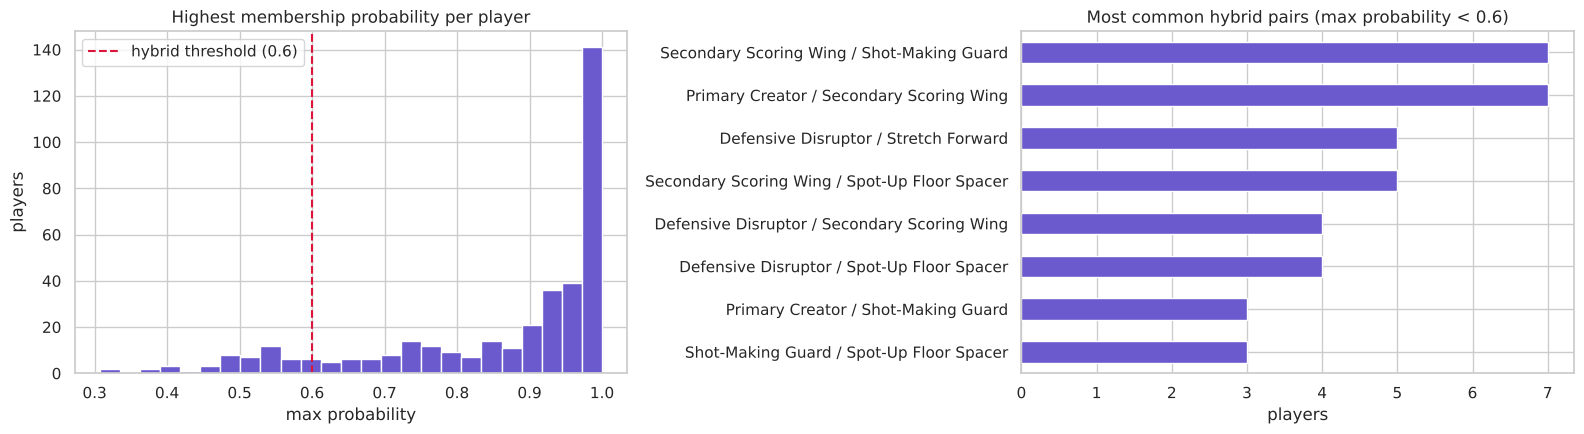

In [12]:
gmm = GaussianMixture(n_components=K, covariance_type='tied', means_init=km8.cluster_centers_,
                      random_state=SEED, max_iter=500).fit(X)
proba = pd.DataFrame(gmm.predict_proba(X), columns=[NAMES[c] for c in range(K)])[ORDER]
top1, top2 = proba.apply(lambda r: r.nlargest(2).index[0], axis=1), proba.apply(lambda r: r.nlargest(2).index[1], axis=1)
pmax = proba.max(axis=1)

print(f'GMM most-likely archetype = k-means label for {(top1 == archetype).mean():.0%} of players '
      f'(ARI {adjusted_rand_score(archetype, top1):.2f})')
print(f'median highest probability: {pmax.median():.2f} | hybrids (max < 0.6): {(pmax < 0.6).sum()} '
      f'players ({(pmax < 0.6).mean():.0%})')

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
ax[0].hist(pmax, bins=25, color='slateblue', edgecolor='white')
ax[0].axvline(0.6, color='crimson', ls='--', label='hybrid threshold (0.6)')
ax[0].set(title='Highest membership probability per player', xlabel='max probability', ylabel='players'); ax[0].legend()
hyb_pairs = pd.Series([' / '.join(sorted([a, b])) for a, b, p in zip(top1, top2, pmax) if p < 0.6]).value_counts()
hyb_pairs.head(8).sort_values().plot.barh(ax=ax[1], color='slateblue')
ax[1].set(title='Most common hybrid pairs (max probability < 0.6)', xlabel='players')
plt.tight_layout(); plt.show()

**Goal.** Show the archetype mix of well-known players, and list the most balanced hybrids in the league.

**What to look for.** Stars whose mix spreads across two archetypes (their game combines two roles), and whether the
hybrid list matches basketball intuition about versatile players.

In [13]:
def mix(i, n=3):
    r = proba.loc[i].nlargest(n)
    return ' · '.join(f'{k} {v:.0%}' for k, v in r.items() if v >= 0.05)

star_idx = [power.index[power['player'] == s][0] for s in STARS]
display(pd.DataFrame({'player': power.loc[star_idx, 'player'].values, 'listed': power.loc[star_idx, 'pos'].values,
                      'k-means archetype': archetype[star_idx].values,
                      'GMM archetype mix': [mix(i) for i in star_idx]}))

hyb = power.loc[pmax < 0.6, ['player', 'pos']].assign(mix=[mix(i) for i in power.index[pmax < 0.6]],
                                                       max_p=pmax[pmax < 0.6].round(2))
print('Most balanced hybrids (lowest maximum probability):')
hyb.nsmallest(12, 'max_p')

,player,listed,k-means archetype,GMM archetype mix
0,Nikola Jokić,C,Hub Big,Hub Big 99%
1,Giannis Antetokounmpo,PF,Hub Big,Hub Big 95% · Primary Creator 5%
2,Shai Gilgeous-Alexander,PG,Primary Creator,Primary Creator 100%
3,Luka Dončić,PG,Primary Creator,Primary Creator 99%
4,Stephen Curry,PG,Primary Creator,Primary Creator 98%
5,Rudy Gobert,C,Rim-Running Big,Rim-Running Big 100%
6,Victor Wembanyama,C,Hub Big,Hub Big 94%
7,Draymond Green,PF,Defensive Disruptor,Stretch Forward 98%
8,LeBron James,SF,Primary Creator,Primary Creator 99%
9,Kevin Durant,SF,Primary Creator,Secondary Scoring Wing 56% · Primary Creator 44%


Most balanced hybrids (lowest maximum probability):


,player,pos,mix,max_p
81,Mohamed Diawara,SF,Spot-Up Floor Spacer 31% · Secondary Scoring Wing 30% · Shot-Making Guard 23%,0.31
169,Jaime Jaquez Jr.,SF,Primary Creator 31% · Secondary Scoring Wing 27% · Stretch Forward 27%,0.31
134,Jaden Hardy,SG,Shot-Making Guard 38% · Secondary Scoring Wing 30% · Primary Creator 26%,0.38
76,Tristan Da Silva,SF,Defensive Disruptor 39% · Stretch Forward 27% · Spot-Up Floor Spacer 20%,0.39
205,Terance Mann,SG,Shot-Making Guard 39% · Secondary Scoring Wing 39% · Defensive Disruptor 17%,0.39
361,Aaron Wiggins,SG,Stretch Forward 40% · Primary Creator 27% · Defensive Disruptor 21%,0.40
247,Zeke Nnaji,PF,Stretch Forward 41% · Hub Big 37% · Secondary Scoring Wing 20%,0.41
201,Brook Lopez,C,Secondary Scoring Wing 43% · Shot-Making Guard 37% · Stretch Forward 9%,0.43
123,Jerami Grant,PF,Defensive Disruptor 45% · Primary Creator 23% · Secondary Scoring Wing 18%,0.45
262,Craig Porter Jr.,PG,Shot-Making Guard 45% · Secondary Scoring Wing 22% · Defensive Disruptor 18%,0.45


### Findings: Soft membership
- The GMM is confident for most players (median highest probability ≈ 0.94), but **about one player in eight is a
  hybrid** (highest probability < 0.6).
- **Hybrids sit between archetypes that are neighbours on the map.** The most common pairs are Secondary Scoring Wing
  with Shot-Making Guard or Primary Creator, then Defensive Disruptor with Stretch Forward. **Secondary Scoring Wing is
  the most frequent partner**, consistent with its central, unstable position (§7). No hybrid mixes, say, a Rim-Running
  Big with a Spot-Up Floor Spacer. This mirrors the play-by-play finding from the EDA, where listed and played
  positions disagreed only between neighbouring slots.
- The most balanced hybrids (Diawara, Jaquez Jr., Hardy, Da Silva, Terance Mann) spread their probability across three
  archetypes, with none above 40%. Brook Lopez, a centre by listing, is split between Secondary Scoring Wing and
  Shot-Making Guard, reflecting a perimeter-heavy shot diet.
- **Kevin Durant** is the archetypal hybrid: a high-usage scorer with modest playmaking, split between Secondary Scoring
  Wing and Primary Creator.
- **GMM and k-means disagree on a share of players** (see the agreement printed above). The tied covariance lets the GMM
  stretch components along correlated directions, so it moves some border players, e.g. Draymond Green, whom the GMM
  places with the Stretch Forwards (big-man rebounding, low usage) rather than the Defensive Disruptors. **Disagreement
  between the two methods is itself a hybrid signal**, and both labels are exported.

---
## 9. Do the Methods and Preprocessing Choices Agree?

**Goal.** Compare the k-means archetypes with (a) the other two methods and (b) k-means run on different inputs, at
both levels of the taxonomy (k = 3 and k = 8).

**Measure: Adjusted Rand Index (ARI).** ARI compares two partitions of the same players, ignoring label names: 1 =
identical groupings, 0 = no more agreement than random labelling. It is the same measure that the validation notebook
will use against listed positions.

| Comparison | Question |
|---|---|
| k-means vs. Ward, GMM | Do different algorithms find the same groups? |
| Power vs. Standard scaling | Does the scaling choice from notebook 02 drive the result? |
| 13 features vs. 3 / 5 PC scores | Does the result depend on the minor dimensions? |

**What to look for.** High agreement at k = 3 confirms the families are robust; agreement at k = 8 shows how much of
the finer structure is method-dependent.

In [14]:
def km(data, k):
    return KMeans(n_clusters=k, n_init=50, random_state=SEED).fit_predict(data)

rows = []
for k in (3, 8):
    ref = km_models[k].labels_
    gm = GaussianMixture(k, covariance_type='tied', means_init=km_models[k].cluster_centers_,
                         random_state=SEED, max_iter=500).fit(X).predict(X)
    alts = {'Ward hierarchical (same features)': fcluster(Z, k, 'maxclust'),
            'GMM tied (same features)': gm,
            'k-means on StandardScaler features': km(standard[FEAT].values, k),
            'k-means on 3 PC scores': km(pcs[['PC1', 'PC2', 'PC3']].values, k),
            'k-means on 5 PC scores': km(pcs[['PC1', 'PC2', 'PC3', 'PC4', 'PC5']].values, k)}
    for name, lab in alts.items():
        rows.append({'comparison': name, 'k': k, 'ARI vs. k-means (power, 13 features)': adjusted_rand_score(ref, lab)})
agree = pd.DataFrame(rows).pivot(index='comparison', columns='k', values='ARI vs. k-means (power, 13 features)')
agree.columns = [f'ARI at k = {c}' for c in agree.columns]
agree.round(2)

,ARI at k = 3,ARI at k = 8
comparison,,
GMM tied (same features),0.58,0.48
Ward hierarchical (same features),0.50,0.48
k-means on 3 PC scores,0.96,0.68
k-means on 5 PC scores,0.90,0.70
k-means on StandardScaler features,0.82,0.62


### Findings: Agreement
- **At k = 3 the families are robust to preprocessing**: ARI 0.96 with k-means on 3 PC scores, 0.90 on 5 PC scores and
  0.82 on StandardScaler features. **Across algorithms, agreement is only moderate** (Ward 0.50, GMM 0.58): all three
  find a big group, a creator group and an off-ball group, but they draw the borders between them in different places,
  most of all for the in-between players (stretch forwards, secondary wings), as expected when the groups lie on a
  continuum.
- **At k = 8 agreement is moderate** (roughly 0.5–0.7). The archetypes are recognisably the same across scalers and
  PC-based inputs, but border players move, which is fully consistent with the per-archetype stability in §7 and the
  hybrid analysis in §8.
- Practical reading: **the family label (3 groups) is a robust fact about the data; the archetype label (8 groups) is a
  useful, interpretable description whose borders are soft.** The exported table carries both, plus GMM probabilities
  for the borders.

---
## 10. Archetypes vs. Listed Positions, and Export

**Goal.** Cross-tabulate archetypes against listed positions, as a preview of the formal validation (ARI against
listed and played positions) in the final notebook.

**What to look for.** Rows (archetypes) spread across many columns (positions) are roles that the position system
cannot express; columns spread across many rows are positions that hide several roles.

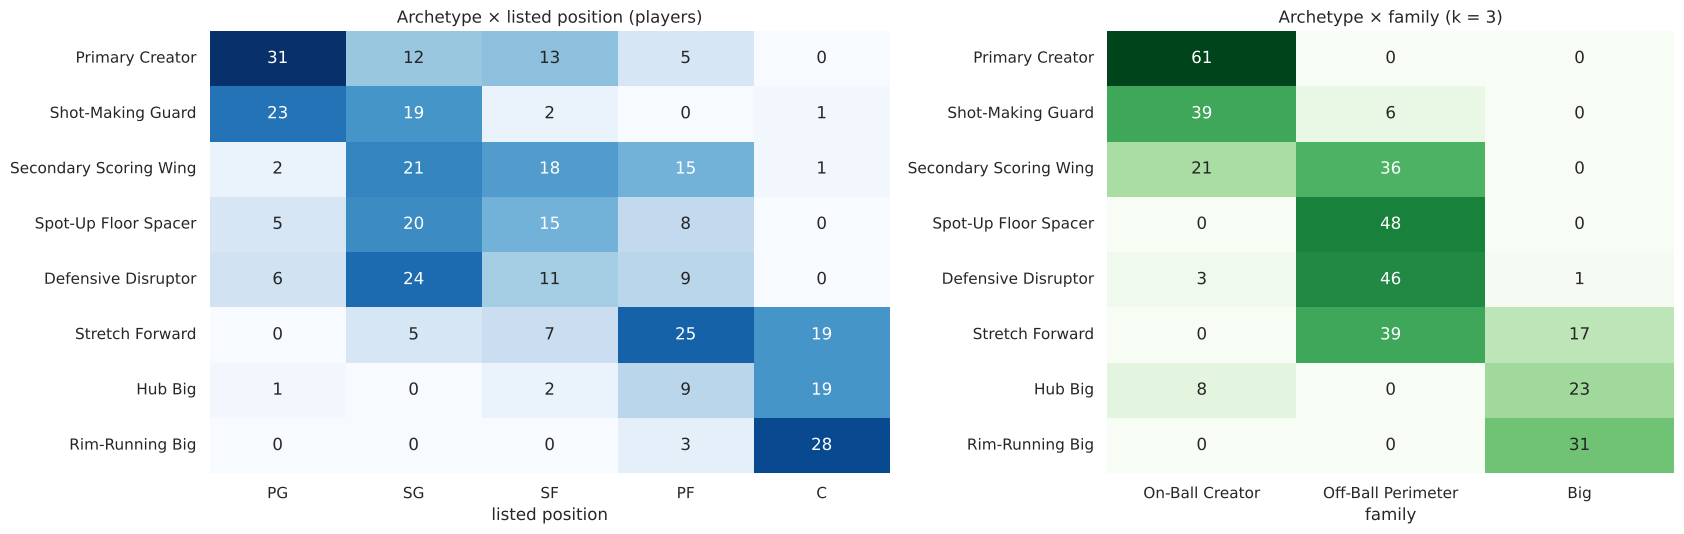

ARI archetypes vs. listed position: 0.14 | families vs. listed position: 0.17


In [15]:
fam_lab = km_models[3].labels_
# name the 3 families through anchor players, as for archetypes
FAM_ANCHORS = {'Rudy Gobert': 'Big', "De'Aaron Fox": 'On-Ball Creator', 'Luguentz Dort': 'Off-Ball Perimeter'}
FAM = {fam_lab[power.index[power['player'] == p][0]]: n for p, n in FAM_ANCHORS.items()}
assert len(FAM) == 3
family = pd.Series([FAM[l] for l in fam_lab], name='family')

ct = pd.crosstab(archetype, power['pos']).loc[ORDER, POS_ORDER]
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={'width_ratios': [1.2, 1]})
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0])
ax[0].set(title='Archetype × listed position (players)', xlabel='listed position', ylabel='')
fa = pd.crosstab(archetype, family).loc[ORDER, ['On-Ball Creator', 'Off-Ball Perimeter', 'Big']]
sns.heatmap(fa, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax[1])
ax[1].set(title='Archetype × family (k = 3)', xlabel='family', ylabel='')
plt.tight_layout(); plt.show()
print(f'ARI archetypes vs. listed position: {adjusted_rand_score(archetype, power["pos"]):.2f} | '
      f'families vs. listed position: {adjusted_rand_score(family, power["pos"]):.2f}')

### Findings: Archetypes vs. positions
- **Most archetypes span three or more listed positions**, and every listed position except C feeds at least four
  archetypes. The archetype system and the position system are measuring different things.
- **ARI between archetypes and listed positions is low**: the clusters are not a re-labelling of positions. Formal
  validation (including against play-by-play positions) follows in the final notebook.
- **Archetypes nest *approximately* inside families**: Primary Creators and Shot-Making Guards are On-Ball Creators;
  Rim-Running Bigs are Bigs; Spot-Up Floor Spacers and Defensive Disruptors are Off-Ball Perimeter. Stretch Forwards and
  Hub Bigs are split between two families, and Secondary Scoring Wings between creators and off-ball players, which is
  exactly where the continuum is.

### Export

**Goal.** Save one row per player with both levels of labels, GMM probabilities and quality indicators, ready for the
anomaly-detection and validation notebooks.

| Column | Meaning |
|---|---|
| `family` | k = 3 label (robust) |
| `archetype` | k = 8 k-means label |
| `gmm_archetype`, `gmm_max_prob`, `hybrid` | GMM most-likely archetype, its probability, and max probability < 0.6 |
| `p_<archetype>` | GMM membership probability for each archetype |
| `silhouette` | the player's silhouette value at k = 8 |

In [16]:
out = DATA / 'processed'
prob_cols = proba.add_prefix('p_')
prob_cols.columns = [c.lower().replace(' ', '_').replace('-', '_') for c in prob_cols.columns]
result = pd.concat([power[META], pcs[['PC1', 'PC2', 'PC3']], family, archetype,
                    pd.DataFrame({'gmm_archetype': top1, 'gmm_max_prob': pmax.round(3), 'hybrid': pmax < 0.6,
                                  'silhouette': sil.round(3)}), prob_cols.round(3)], axis=1)
result.to_csv(out / 'archetypes.csv', index=False)
profile.to_csv(out / 'archetype_profiles.csv')
print('saved', out / 'archetypes.csv', result.shape)
print('saved', out / 'archetype_profiles.csv', profile.shape)
result[['player', 'pos', 'family', 'archetype', 'gmm_archetype', 'gmm_max_prob', 'hybrid']].head()

saved ../data/processed/archetypes.csv (379, 30)
saved ../data/processed/archetype_profiles.csv (8, 17)


,player,pos,family,archetype,gmm_archetype,gmm_max_prob,hybrid
0,Precious Achiuwa,C,Big,Stretch Forward,Hub Big,0.908,False
1,Steven Adams,C,Big,Rim-Running Big,Rim-Running Big,1.000,False
2,Bam Adebayo,C,On-Ball Creator,Hub Big,Secondary Scoring Wing,0.878,False
3,Ochai Agbaji,SG,Off-Ball Perimeter,Stretch Forward,Stretch Forward,0.994,False
4,Santi Aldama,PF,Off-Ball Perimeter,Stretch Forward,Stretch Forward,0.936,False


---
## Summary

| Question | Answer |
|---|---|
| Is there strong cluster structure? | **No:** silhouette ≤ 0.21 at every k. Roles form a continuum, consistent with EDA and PCA |
| Statistically best k | **3** (silhouette, Calinski-Harabasz, Davies-Bouldin, tied-GMM BIC and dendrogram gaps all agree; stability ≈ 0.84) |
| Three families | **On-Ball Creator · Off-Ball Perimeter · Big**: robust to scaler and input (ARI 0.82–0.96); borders drawn differently by Ward / GMM (ARI 0.50–0.58) |
| Eight archetypes | Primary Creator · Shot-Making Guard · Secondary Scoring Wing · Spot-Up Floor Spacer · Defensive Disruptor · Stretch Forward · Hub Big · Rim-Running Big |
| Archetype reliability | Rim-Running Big highly stable; Spot-Up, Stretch Forward and Primary Creator valid; Secondary Scoring Wing unstable ("versatile / no specialty") |
| Soft membership | Tied GMM: about 1 in 8 players is a hybrid (max probability < 0.6), always between neighbouring archetypes |
| Relation to positions | Archetypes cross listed positions freely; low ARI with listed position |

**Next: `05_Anomalies.ipynb`.** Isolation Forest and Local Outlier Factor on the StandardScaler features (which keep
genuine extremes extreme), compared with DBSCAN noise points, to find the league's statistically one-of-a-kind
players, and to check whether they are the hybrids or the extreme ends of an archetype.